# Stock Price vs. Revenue: Tesla and GameStop

**Author:** Todd Sakai | **Tools:** Python, pandas, yfinance, requests, BeautifulSoup, Matplotlib

Final project for *Python Project for Data Science* (IBM Data Science Professional Certificate, Coursera).

## Summary

This project collects two kinds of data for Tesla (TSLA) and GameStop (GME) and puts them on one dashboard:

1. **Daily share prices**, pulled with the `yfinance` API.
2. **Quarterly revenue**, scraped from HTML tables with `requests` and `BeautifulSoup`, then cleaned with pandas.

The question is simple: **does a company's share price follow its revenue?** The two stocks give opposite answers. Tesla's price rose with fast revenue growth. GameStop's price jumped in January 2021 while its revenue was falling, so its price moved for reasons that revenue does not explain.

## Contents

- Setup and the graphing function
- Extract Tesla stock data (yfinance)
- Scrape Tesla revenue data
- Extract GameStop stock data (yfinance)
- Scrape GameStop revenue data
- Dashboards for Tesla and GameStop
- Extra analysis: revenue growth and price compared with revenue
- Findings

## Setup

Requires `yfinance`, `beautifulsoup4`, `pandas` and `matplotlib`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import requests
import yfinance as yf
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore", category=FutureWarning)

### Graphing function

`make_graph` draws the share price above the revenue on a shared date axis. It takes a stock DataFrame (`Date`, `Close`), a revenue DataFrame (`Date`, `Revenue`) and a company name. The course fixes the cutoff at June 2021.

In [2]:
def make_graph(stock_data, revenue_data, stock):
    stock_data_specific = stock_data[stock_data.Date <= "2021-06-14"]
    revenue_data_specific = revenue_data[revenue_data.Date <= "2021-04-30"]

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    axes[0].plot(pd.to_datetime(stock_data_specific.Date),
                 stock_data_specific.Close.astype("float"),
                 label="Share Price", color="blue")
    axes[0].set_ylabel("Price ($US)")
    axes[0].set_title(f"{stock} - Historical Share Price")

    axes[1].plot(pd.to_datetime(revenue_data_specific.Date),
                 revenue_data_specific.Revenue.astype("float"),
                 label="Revenue", color="green")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].set_title(f"{stock} - Historical Revenue")

    plt.tight_layout()
    plt.show()

### Helper functions

The same steps run for both companies, so they are written once.

- `get_stock_history` downloads the full price history and removes the time zone from the dates, so that they compare cleanly with plain date strings.
- `scrape_revenue` downloads a page, finds the quarterly revenue table, and returns clean `Date` and `Revenue` columns. It removes `$` and `,` and drops empty rows.

In [3]:
def get_stock_history(ticker_symbol):
    ticker = yf.Ticker(ticker_symbol)
    data = ticker.history(period="max")
    data = data.reset_index()
    data["Date"] = pd.to_datetime(data["Date"]).dt.tz_localize(None)
    return data


def scrape_revenue(url, table_index=1):
    html_data = requests.get(url, timeout=30).text
    soup = BeautifulSoup(html_data, "html.parser")

    rows = []
    for row in soup.find_all("tbody")[table_index].find_all("tr"):
        cols = row.find_all("td")
        if len(cols) >= 2:
            rows.append({"Date": cols[0].text.strip(), "Revenue": cols[1].text.strip()})

    revenue = pd.DataFrame(rows, columns=["Date", "Revenue"])
    revenue["Revenue"] = revenue["Revenue"].str.replace(r",|\$", "", regex=True)
    revenue = revenue.dropna()
    revenue = revenue[revenue["Revenue"] != ""]
    return revenue

## Extract Tesla stock data with yfinance

In [4]:
tesla_data = get_stock_history("TSLA")
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Scrape Tesla quarterly revenue

In [5]:
TESLA_URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
             "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm")

tesla_revenue = scrape_revenue(TESLA_URL)
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Extract GameStop stock data with yfinance

In [6]:
gme_data = get_stock_history("GME")
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Scrape GameStop quarterly revenue

In [7]:
GME_URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
           "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html")

gme_revenue = scrape_revenue(GME_URL)
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Dashboards

### Tesla

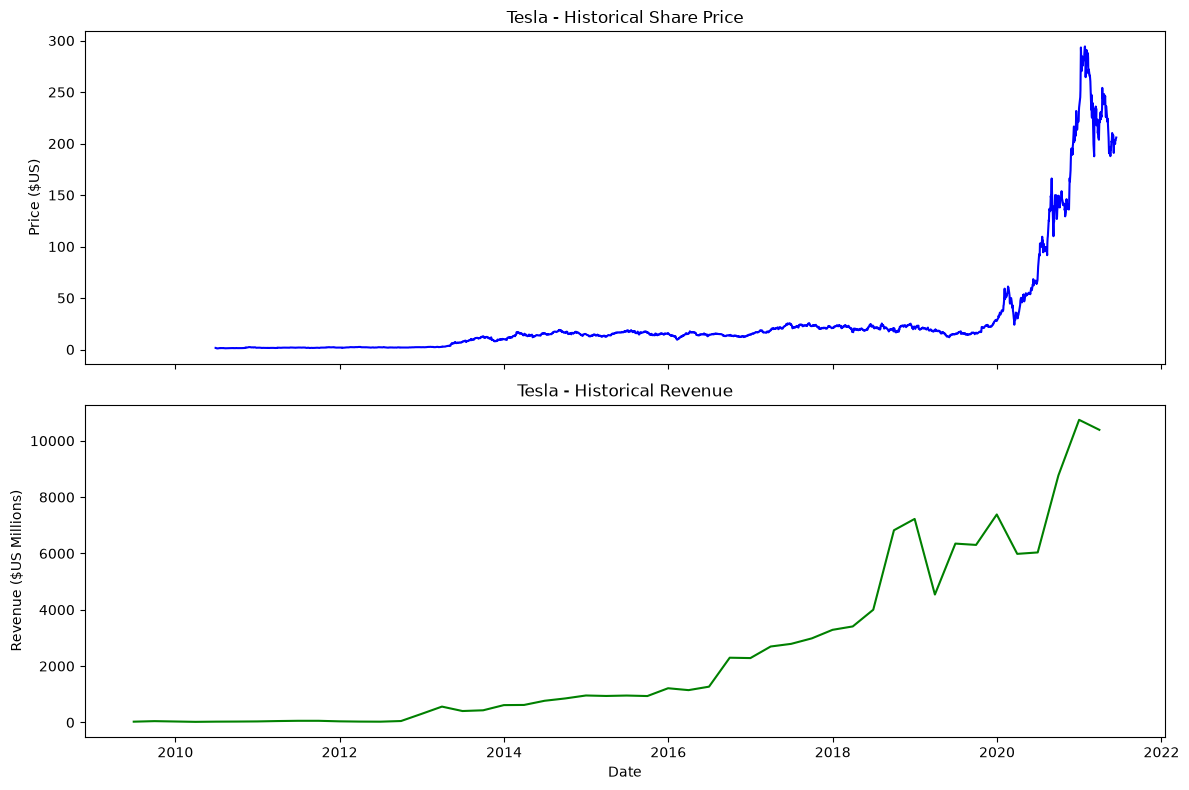

In [8]:
make_graph(tesla_data, tesla_revenue, "Tesla")

### GameStop

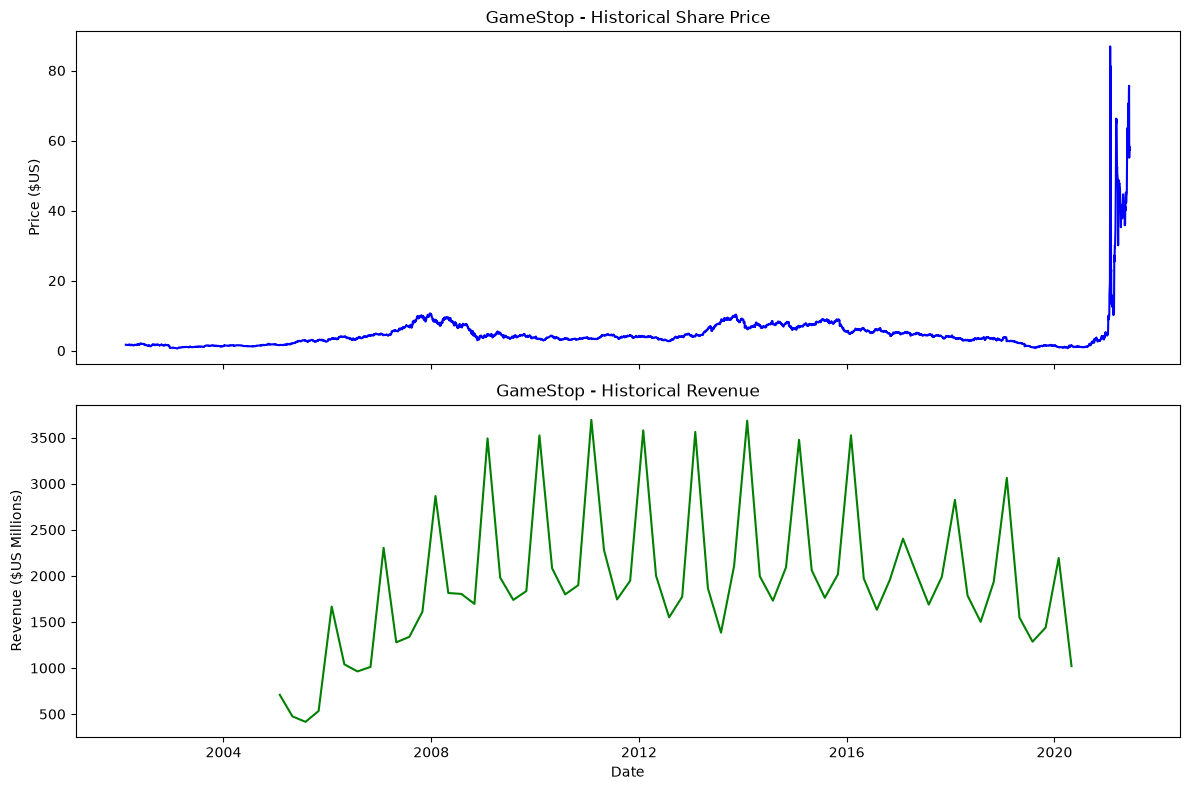

In [9]:
make_graph(gme_data, gme_revenue, "GameStop")

## Extra analysis: growth, and price compared with revenue

The charts show the trend. This section adds numbers.

1. **Year-over-year revenue growth:** each quarter compared with the same quarter one year before, which removes seasonal effects such as GameStop's holiday quarter.
2. **Price compared with revenue:** each quarter's revenue is matched to the closing price on the last trading day of that quarter. A correlation near +1 means that price and revenue moved together. Correlation does not show cause.

In [10]:
def quarterly_view(stock_data, revenue_data, cutoff="2021-04-30"):
    rev = revenue_data.copy()
    # merge_asof needs both Date columns at the same time precision.
    rev["Date"] = pd.to_datetime(rev["Date"]).astype("datetime64[ns]")
    rev["Revenue"] = rev["Revenue"].astype(float)
    rev = rev[rev["Date"] <= cutoff].sort_values("Date")
    rev["YoY growth %"] = rev["Revenue"].pct_change(4) * 100

    prices = stock_data[["Date", "Close"]].copy()
    prices["Date"] = prices["Date"].astype("datetime64[ns]")
    prices = prices.sort_values("Date")
    merged = pd.merge_asof(rev, prices, on="Date", direction="backward")
    return merged.rename(columns={"Close": "Quarter-end close"})


def summarize(name, view):
    v = view.dropna(subset=["Quarter-end close"])
    corr = v["Revenue"].corr(v["Quarter-end close"])
    last = view.dropna(subset=["YoY growth %"]).tail(4)["YoY growth %"].mean()
    print(f"{name}: {len(v)} quarters matched to a price")
    print(f"  Correlation of revenue with quarter-end price: {corr:.2f}")
    print(f"  Mean YoY revenue growth, last 4 quarters:      {last:.1f}%")


tesla_q = quarterly_view(tesla_data, tesla_revenue)
gme_q = quarterly_view(gme_data, gme_revenue)

summarize("Tesla", tesla_q)
summarize("GameStop", gme_q)

Tesla: 44 quarters matched to a price
  Correlation of revenue with quarter-end price: 0.76
  Mean YoY revenue growth, last 4 quarters:      38.3%
GameStop: 62 quarters matched to a price
  Correlation of revenue with quarter-end price: 0.16
  Mean YoY revenue growth, last 4 quarters:      -25.6%


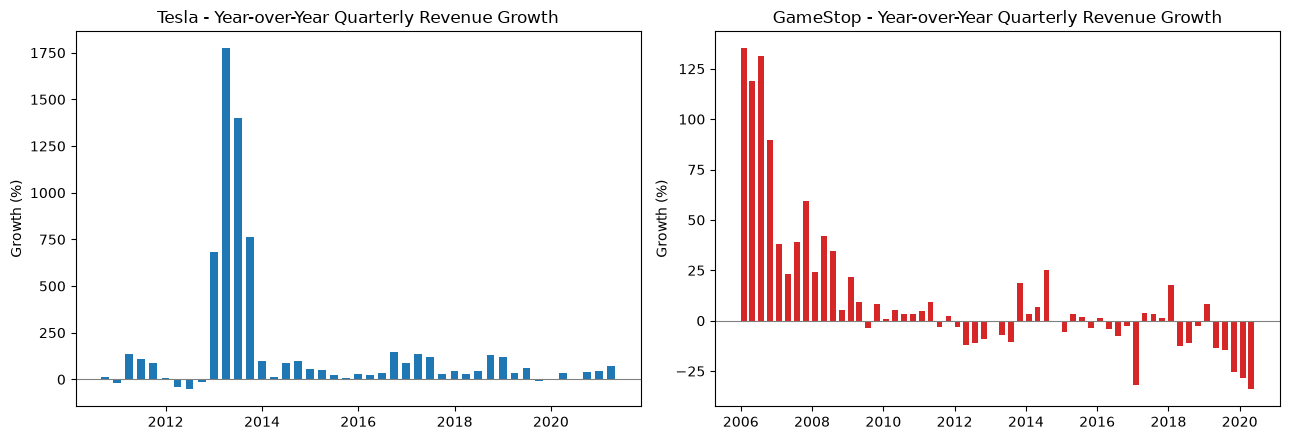

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, view, color) in zip(axes, [("Tesla", tesla_q, "tab:blue"),
                                          ("GameStop", gme_q, "tab:red")]):
    v = view.dropna(subset=["YoY growth %"])
    ax.bar(v["Date"], v["YoY growth %"], width=60, color=color)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"{name} - Year-over-Year Quarterly Revenue Growth")
    ax.set_ylabel("Growth (%)")
plt.tight_layout()
plt.show()

## Findings

- **Tesla:** Revenue grew fast over most of the period, and by 38% a year over the last four quarters. The share price rose with it (correlation 0.76). The large rise came in 2020. The price grew much faster than revenue, so investors were paying for expected growth and not only for current sales.
- **GameStop:** Revenue was flat or falling for years. In January 2021 the share price jumped many times over in a few weeks, during the short squeeze (a fast rise that forces short sellers to buy back shares), with no matching change in revenue (correlation only 0.16, and revenue down 26% from a year earlier).
- **Lesson for risk work:** Fundamentals such as revenue explain a price only part of the time. A risk model that uses only fundamentals would miss a GameStop-style event. That is why market risk measures also use price volatility and position data.

## What I learned

- Pulling market data from an API (`yfinance`) and turning web tables into clean DataFrames (`requests`, `BeautifulSoup`).
- Cleaning text values into numbers, and handling dates with time zones before a comparison.
- Joining two time series that have different frequencies (daily prices and quarterly revenue) with `merge_asof`.